In [1]:
print("Hello, Python!")

Hello, Python!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import zipfile

zip_file = "house-prices-advanced-regression-techniques.zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("house_prices")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
import os

print(os.listdir("house_prices"))

['data_description.txt', 'sample_submission.csv', 'test.csv', 'train.csv']


In [5]:
df = pd.read_csv("house_prices/train.csv")

print("Dataset loaded successfully!")
print(df.shape)


Dataset loaded successfully!
(1460, 81)


In [6]:
print(df.head())


   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

In [7]:
print(df.isnull().sum().sort_values(ascending=False).head(10))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64


In [8]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1460, 80)
Target: (1460,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 80)
Testing data: (292, 80)


In [10]:
# Convert text columns into numbers
X = pd.get_dummies(X, drop_first=True)

# Fill missing values with the median
X = X.fillna(X.median(numeric_only=True))

print("Data prepared successfully!")
print("Number of features:", X.shape[1])
print("Missing values:", X.isnull().sum().sum())

Data prepared successfully!
Number of features: 245
Missing values: 0


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 245)
Testing data: (292, 245)


In [12]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [13]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print(y_pred[:5])

Predictions completed!
[158019.21567875 337216.21531882  83203.9974987  182061.89022264
 324072.78655971]


In [14]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)

Mean Squared Error: 1107935981.6348171
Root Mean Squared Error: 33285.67231760261
R² Score: 0.8555555589543666


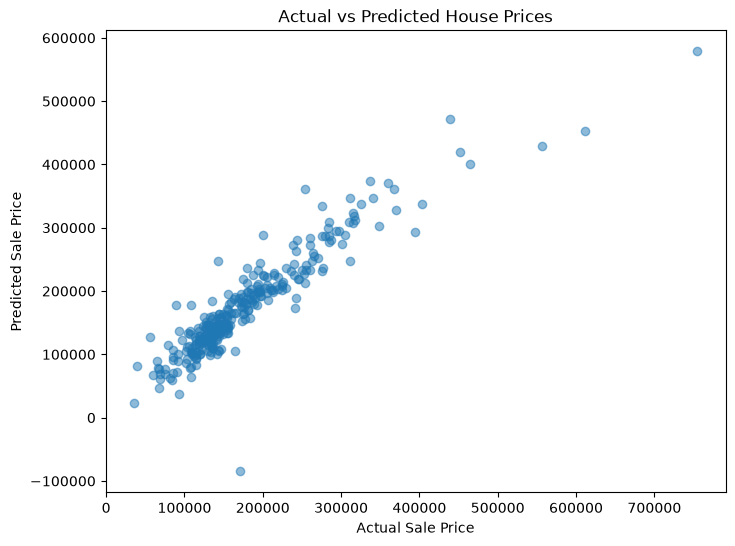

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [16]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0        154500    158019.215679
1        325000    337216.215319
2        115000     83203.997499
3        159000    182061.890223
4        315500    324072.786560
5         75500     68624.780563
6        311500    247507.440961
7        146000    145987.852543
8         84500     60058.337790
9        135500    155433.530666
